# ADMIXTURE v. RFmix global ancestry proportions
Ran ADMIXTURE two different ways:
1. Project all 340 samples onto reference panel
2. Project unrelated samples onto reference, project related samples onto unrelated

##### Modules

In [36]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib import font_manager

import scipy.stats as stats

##### Fonts & Colors

In [55]:
# font style
locations = ['/home/eger/software/fonts']
font_files = font_manager.findSystemFonts(fontpaths = locations)
for file in font_files:
    font_manager.fontManager.addfont(file)
plt.rcParams['font.family'] = 'Aptos'

# font size
title_size = 24
label_size = 18
tick_size = 16

# colors
E280A_color = 'skyblue'
anc_color_dict = {'EUR': 'dodgerblue', 'AMR': 'green', 'AFR': 'purple'}

##### Inputs

In [3]:
DIR1 = '/scratch/eger/projects/E280A_SNP_arrays/E280A_340/ADMIXTURE_v1'
DIR2 = '/scratch/eger/projects/E280A_SNP_arrays/RFmix_LAI_v2/EstimateGlobalAncestry'

fam1 = os.path.join(DIR1, 'E280A_340.auto.hg38.ext.pruned.fam')
fam2 = os.path.join(DIR1, 'E280A_unrels.auto.hg38.ext.pruned.fam')
fam3 = os.path.join(DIR1, 'E280A_rels.auto.hg38.ext.pruned.fam')

q1 = os.path.join(DIR1, 'E280A_340.auto.hg38.ext.pruned.3.Q')
q2 = os.path.join(DIR1, 'E280A_unrels.auto.hg38.ext.pruned.3.Q')
q3 = os.path.join(DIR1, 'E280A_rels.auto.hg38.ext.pruned.3.Q')

lai_global = os.path.join(DIR2, 'E280A_LAI.lai_global.txt')

In [48]:
df1 = pd.concat([pd.read_csv(fam1, sep='\s+', header=None, 
                             names=['FID', 'IID', 'FA', 'MO', 'SEX', 'PHENO']),
                 pd.read_csv(q1, header=None, sep=' ', names=['AMR', 'EUR', 'AFR'])],
                 axis=1)

df2 = pd.concat([pd.concat([pd.read_csv(fam2, sep='\s+', header=None, 
                             names=['FID', 'IID', 'FA', 'MO', 'SEX', 'PHENO']),
                             pd.read_csv(q2, header=None, sep=' ', names=['Split_AMR', 'Split_EUR', 'Split_AFR'])],
                             axis=1),
                 pd.concat([pd.read_csv(fam3, sep='\s+', header=None, 
                             names=['FID', 'IID', 'FA', 'MO', 'SEX', 'PHENO']),
                             pd.read_csv(q3, header=None, sep=' ', names=['Split_AMR', 'Split_EUR', 'Split_AFR'])],
                             axis=1)])

df3 = pd.read_csv(lai_global, sep='\s+', skiprows=1, header=None, 
                  names=['IID', 'RFmix_AFR', 'RFmix_AMR', 'RFmix_EUR'])

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:15: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_675552/1569038952.py:1: SyntaxWarning: invalid escape sequence '\s'
  df1 = pd.concat([pd.read_csv(fam1, sep='\s+', header=None,
/tmp/ipykernel_675552/1569038952.py:6: SyntaxWarning: invalid escape sequence '\s'
  df2 = pd.concat([pd.concat([pd.read_csv(fam2, sep='\s+', header=None,
/tmp/ipykernel_675552/1569038952.py:10: SyntaxWarning: invalid escape sequence '\s'
  pd.concat([pd.read_csv(fam3, sep='\s+', header=None,
/tmp/ipykernel_675552/1569038952.py:15: SyntaxWarning: invalid escape sequence '\s'
  df3 = pd.read_csv(lai_global, sep='\s+', skiprows=1, header=None,


### ADMIXTURE: compare the two runs

In [49]:
df = df1.merge(df2, on=['FID', 'IID', 'FA', 'MO', 'SEX', 'PHENO'], how='inner')

for anc in anc_color_dict.keys():
    print(df[df[anc] != df['Split_'+anc]])

Empty DataFrame
Columns: [FID, IID, FA, MO, SEX, PHENO, AMR, EUR, AFR, Split_AMR, Split_EUR, Split_AFR]
Index: []
Empty DataFrame
Columns: [FID, IID, FA, MO, SEX, PHENO, AMR, EUR, AFR, Split_AMR, Split_EUR, Split_AFR]
Index: []
Empty DataFrame
Columns: [FID, IID, FA, MO, SEX, PHENO, AMR, EUR, AFR, Split_AMR, Split_EUR, Split_AFR]
Index: []


They are all the same.

### ADMIXTURE: barplot

In [164]:
df = df1.copy()
df.index = df['IID']
df = df[['EUR', 'AMR', 'AFR']]

# Next we want to assign each individual to a population, based on highest proportion of ancestry.
# For each row, we find the column with the greatest value, then assign it that column label value
# in a new column called 'assignment'.
df['assignment'] = df.idxmax(axis=1)

df = df.sort_values(['EUR', 'AMR', 'AFR'], ascending=True)

In [165]:
df['assignment'].value_counts()

assignment
EUR    337
AMR      2
AFR      1
Name: count, dtype: int64

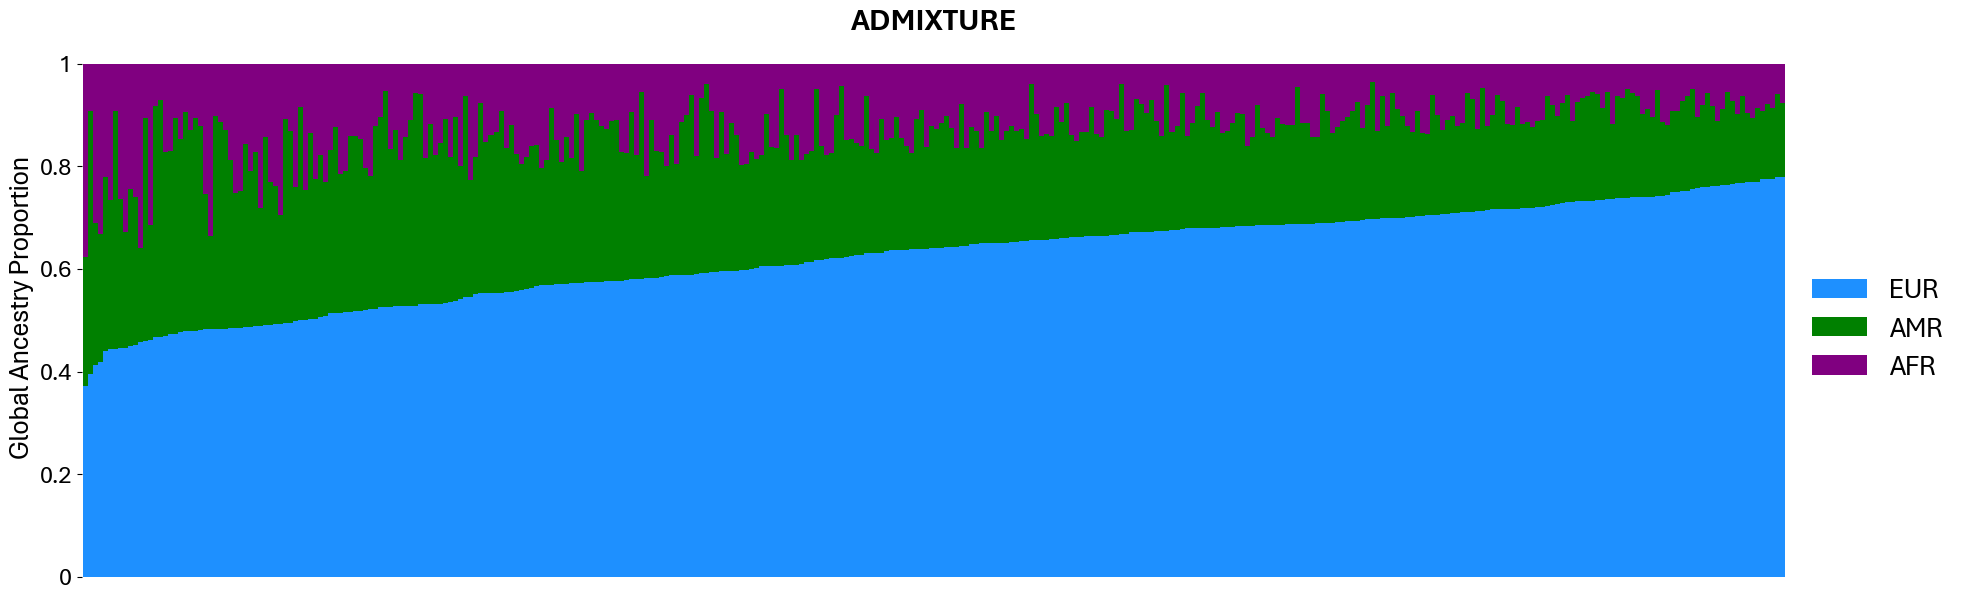

In [166]:
ax = df.plot.bar(stacked=True, 
            figsize=(22, 7),
                    width=1,
                    color=anc_color_dict.values(), 
                    edgecolor=None, 
                    linewidth=0.5)

ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xlabel('')
ax.set_ylabel('Global Ancestry Proportion', fontsize=20)
ax.set_xticks([])
ax.set_yticks([0, .2, .4, .6, .8, 1])
ax.set_yticklabels([0, .2, .4, .6, .8, 1], fontsize=18)
ax.set_title('ADMIXTURE', fontsize=22, fontweight='bold')
ax.legend(bbox_to_anchor=(1,0.6), labelspacing=0.5, fontsize=20, frameon=False)
plt.show()

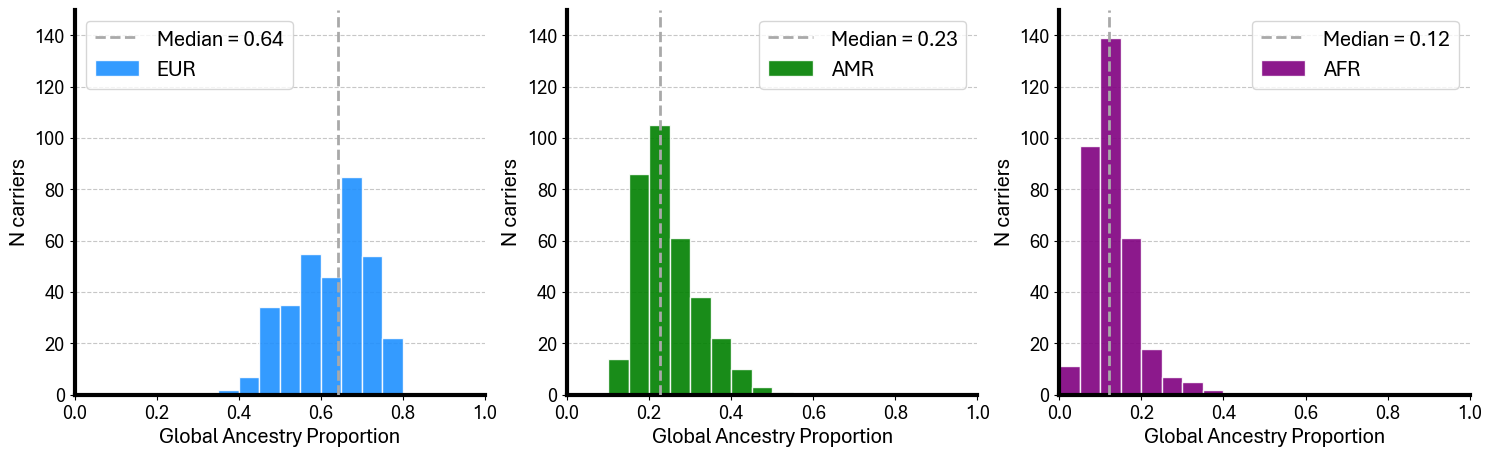

In [136]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i,anc in enumerate(anc_color_dict.keys()):
    ax = axes[i]
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(3)
    ax.spines['left'].set_linewidth(3)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

    # make a histogram
    counts, bins = np.histogram(df[anc], np.arange(0, 1.1, 0.05))

    ax.bar(bins[:-1], counts, width=0.05, align='edge',
        alpha=0.9, color=anc_color_dict[anc], edgecolor='white', zorder=2,
        label=anc)

    # add vertical line for median
    ax.axvline(df[anc].median(), color='darkgray', linestyle='--', 
               linewidth=2, zorder=4, 
               label='Median = {:,}'.format(round(df[anc].median(), 2)))

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 150)
    ax.tick_params(axis='both', labelsize=14)
    ax.set_xlabel('Global Ancestry Proportion', fontsize=16)
    ax.set_ylabel('N carriers', fontsize=16)
    ax.legend(fontsize=16)

plt.show()

### RFmix: barplot

In [167]:
df = df3[df3['IID'].isin(df1['IID'])]
df.index = df['IID']
df = df[['RFmix_EUR', 'RFmix_AMR', 'RFmix_AFR']]

# Next we want to assign each individual to a population, based on highest proportion of ancestry.
# For each row, we find the column with the greatest value, then assign it that column label value
# in a new column called 'assignment'.
df['assignment'] = df.idxmax(axis=1)

df = df.sort_values(['RFmix_EUR', 'RFmix_AMR', 'RFmix_AFR'], ascending=True)

In [168]:
df['assignment'].value_counts()

assignment
RFmix_EUR    337
RFmix_AMR      3
Name: count, dtype: int64

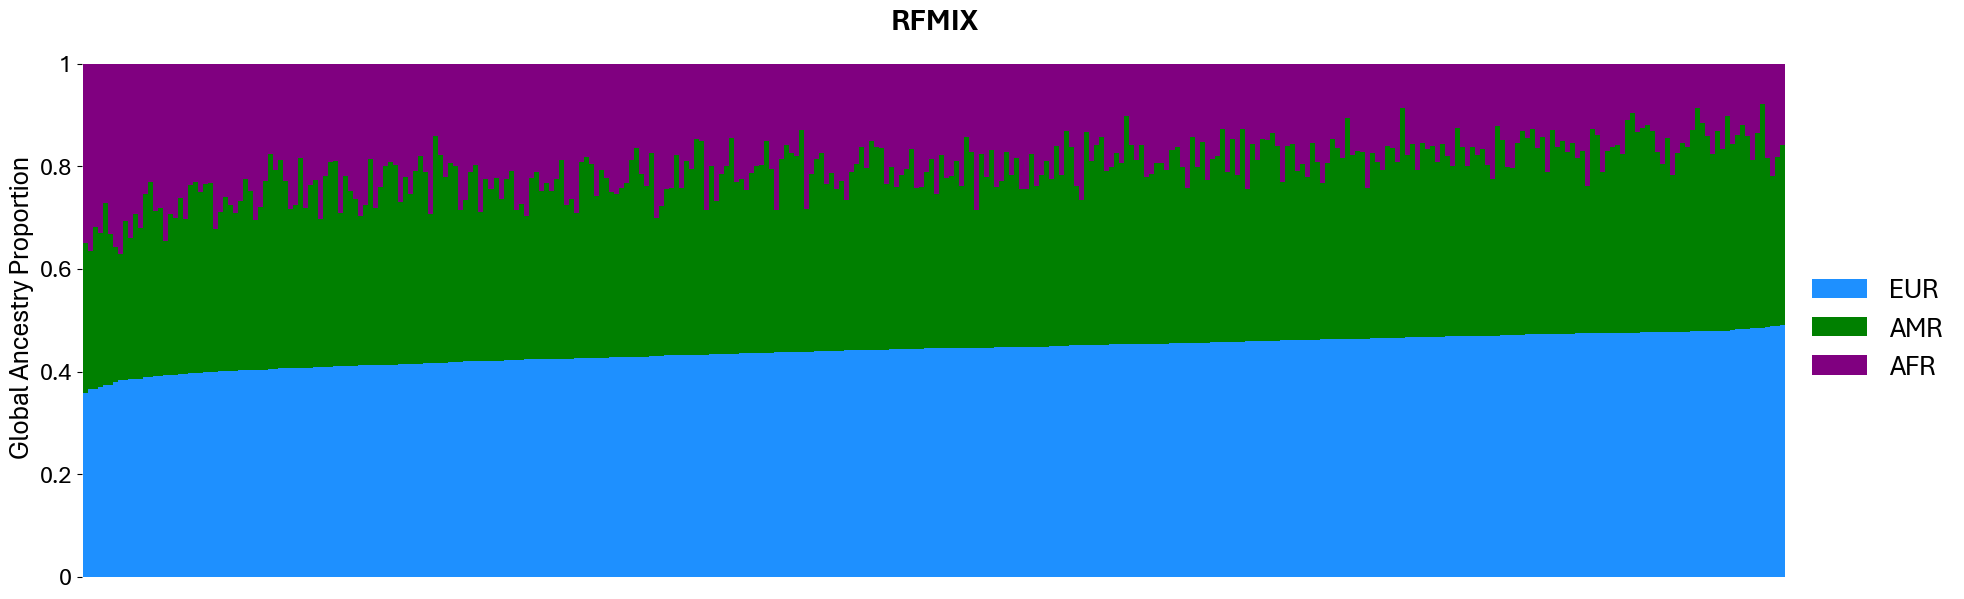

In [162]:
ax = df.plot.bar(stacked=True, 
            figsize=(22, 7),
                    width=1,
                    color=anc_color_dict.values(), 
                    edgecolor=None, 
                    linewidth=0.5)

ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.set_xlabel('')
ax.set_ylabel('Global Ancestry Proportion', fontsize=20)
ax.set_xticks([])
ax.set_yticks([0, .2, .4, .6, .8, 1])
ax.set_yticklabels([0, .2, .4, .6, .8, 1], fontsize=18)
ax.set_title('RFMIX', fontsize=22, fontweight='bold')
ax.legend(['EUR', 'AMR', 'AFR'],
          bbox_to_anchor=(1,0.6), labelspacing=0.5, fontsize=20, frameon=False)
plt.show()

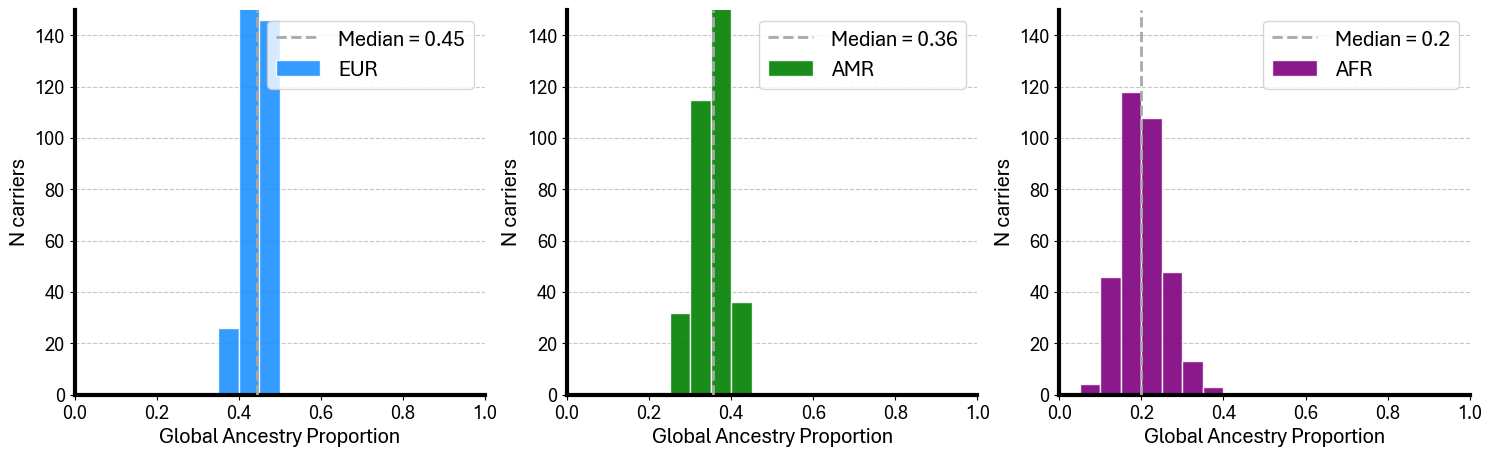

In [170]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i,anc in enumerate(anc_color_dict.keys()):
    ax = axes[i]
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(3)
    ax.spines['left'].set_linewidth(3)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

    # make a histogram
    counts, bins = np.histogram(df['RFmix_'+anc], np.arange(0, 1.1, 0.05))

    ax.bar(bins[:-1], counts, width=0.05, align='edge',
        alpha=0.9, color=anc_color_dict[anc], edgecolor='white', zorder=2,
        label=anc)

    # add vertical line for median
    ax.axvline(df['RFmix_'+anc].median(), color='darkgray', linestyle='--', 
               linewidth=2, zorder=4, 
               label='Median = {:,}'.format(round(df['RFmix_'+anc].median(), 2)))

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 150)
    ax.tick_params(axis='both', labelsize=14)
    ax.set_xlabel('Global Ancestry Proportion', fontsize=16)
    ax.set_ylabel('N carriers', fontsize=16)
    ax.legend(fontsize=16)

plt.show()

### ADMIXTURE v. RFmix

In [171]:
df = df1[['IID', 'AFR','AMR', 'EUR']].merge(df3, on=['IID'], how='inner')

In [172]:
df

,IID,AFR,AMR,EUR,RFmix_AFR,RFmix_AMR,RFmix_EUR
0,B2_54,0.134467,0.179883,0.685650,0.1698,0.3557,0.4745
1,B2_206,0.134300,0.184135,0.681565,0.2099,0.3376,0.4525
2,B2_245,0.132320,0.191063,0.676617,0.2164,0.3399,0.4437
3,B2_275,0.101684,0.172147,0.726169,0.1908,0.3428,0.4664
4,B2_342,0.108238,0.253583,0.638180,0.1984,0.3318,0.4698
...,...,...,...,...,...,...,...
335,17081,0.111050,0.312632,0.576319,0.1861,0.3745,0.4394
336,17627,0.058017,0.413997,0.527986,0.1010,0.4452,0.4538
337,17764,0.377427,0.251375,0.371198,0.3301,0.2995,0.3703
338,17765,0.310700,0.275723,0.413577,0.2935,0.3125,0.3940


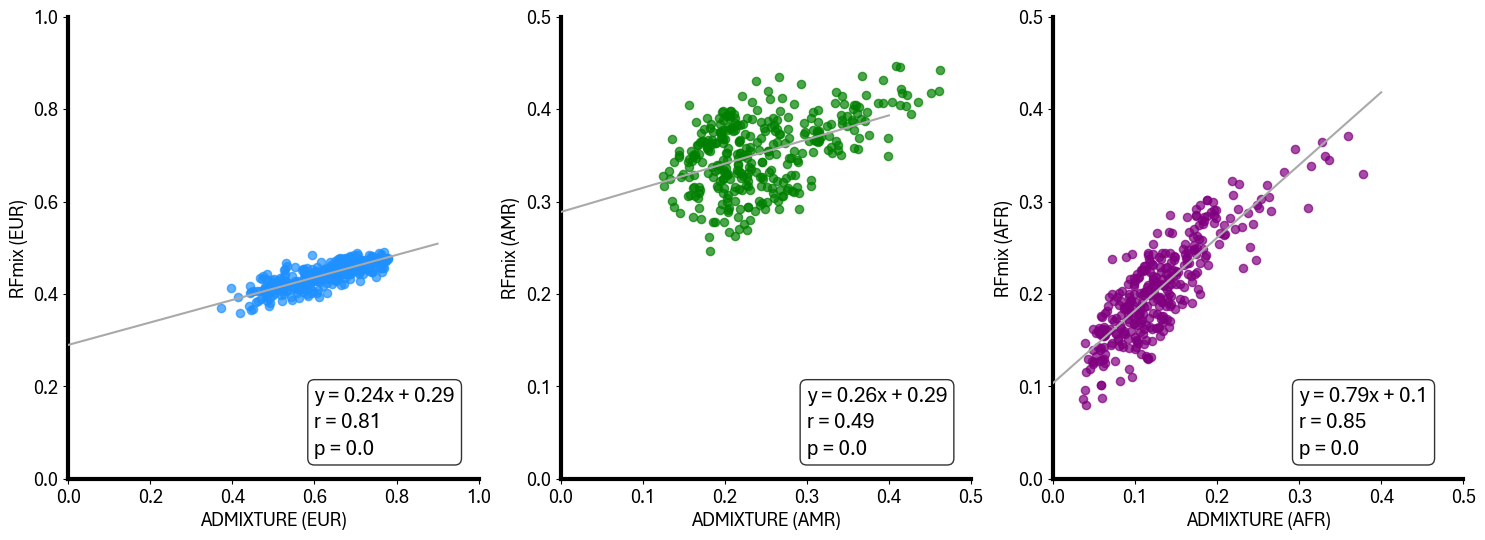

In [184]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i,anc in enumerate(anc_color_dict.keys()):
    x_var = anc
    y_var = 'RFmix_'+anc
    
    
    ax = axes[i]
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(3)
    ax.spines['left'].set_linewidth(3)

    ax.scatter(df[x_var], df[y_var], 
               color=anc_color_dict[anc],
               s=35, alpha=0.7, zorder=3)    

    # Calculate the linear regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        df[x_var], df[y_var])
        
    # regression line stats
    stats_text = '\n'.join(['y = '+str(slope.round(2))+'x + '+str(intercept.round(2)),
                            'r = %s' % str(r_value.round(2)),
                            'p = %s' % str(p_value.round(4))])
    ax.text(0.6, 0.2, stats_text,
        transform=ax.transAxes, fontsize=16, verticalalignment='top',
        horizontalalignment='left',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=0.8),
        linespacing=1.5
    )

    if anc == 'EUR':
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.plot(np.arange(0, 1, 0.1), 
                intercept + slope * np.arange(0, 1, 0.1), 
                color='darkgray', linestyle='-', zorder=4)
    else:
        ax.set_xlim(0, 0.5)
        ax.set_ylim(0, 0.5)
        ax.plot(np.arange(0, 0.5, 0.1), 
                intercept + slope * np.arange(0, 0.5, 0.1), 
                color='darkgray', linestyle='-', zorder=4)
    
    ax.tick_params(axis='both', labelsize=14)
    ax.set_xlabel('ADMIXTURE ('+anc+')', fontsize=14)
    ax.set_ylabel('RFmix ('+anc+')', fontsize=14)

plt.show()

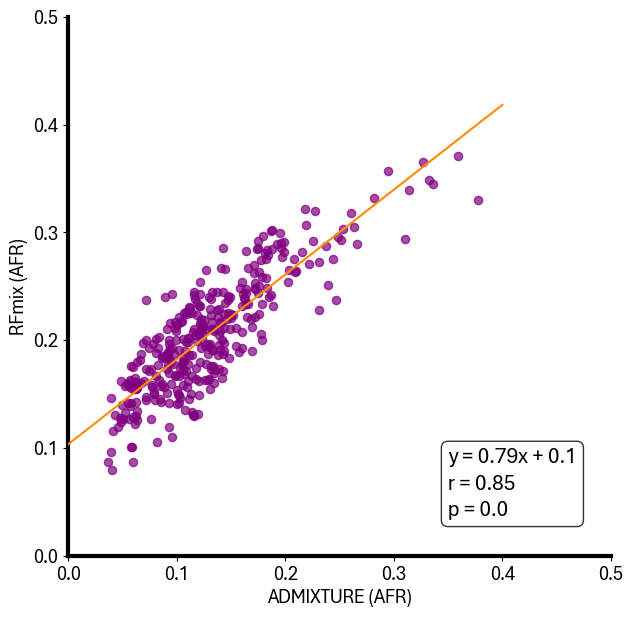

In [84]:
anc = 'AFR'
x_var = anc
y_var = 'RFmix_'+anc
lower, upper = (0, 0.5)

fig, ax = plt.subplots(figsize=(7, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
#ax.grid(True, axis='both', linestyle='--', alpha=0.7, zorder=0)
ax.tick_params(axis='both', labelsize=14)

ax.scatter(df[x_var], df[y_var], color=anc_color_dict[anc],
           s=35, alpha=0.7, zorder=3)    

# Calculate the linear regression line
slope, intercept, r_value, p_value, std_err = stats.linregress(
    df[x_var], df[y_var])
    
# Plot the regression line
ax.plot(np.arange(lower, upper, 0.1), 
        intercept + slope * np.arange(lower, upper, 0.1), 
       color='darkorange', linestyle='-', zorder=4)

# regression line stats
stats_text = '\n'.join(['y = '+str(slope.round(2))+'x + '+str(intercept.round(2)),
                        'r = %s' % str(r_value.round(2)),
                        'p = %s' % str(p_value.round(4))])
ax.text(0.7, 0.2, stats_text,
    transform=ax.transAxes, fontsize=16, verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=0.8),
    linespacing=1.5
)

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_xlabel('ADMIXTURE ('+anc+')', fontsize=14)
ax.set_ylabel('RFmix ('+anc+')', fontsize=14)

plt.show()

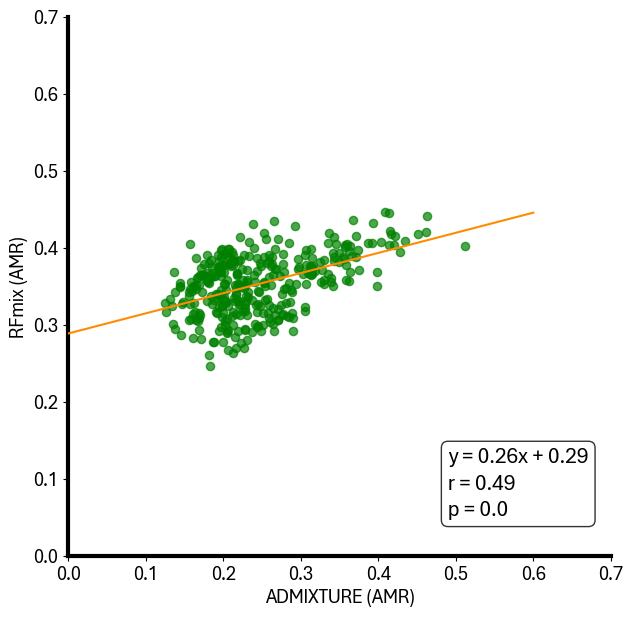

In [87]:
anc = 'AMR'
x_var = anc
y_var = 'RFmix_'+anc
lower, upper = (0, 0.7)

fig, ax = plt.subplots(figsize=(7, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
#ax.grid(True, axis='both', linestyle='--', alpha=0.7, zorder=0)
ax.tick_params(axis='both', labelsize=14)

ax.scatter(df[x_var], df[y_var], color=anc_color_dict[anc],
           s=35, alpha=0.7, zorder=3)    

# Calculate the linear regression line
slope, intercept, r_value, p_value, std_err = stats.linregress(
    df[x_var], df[y_var])
    
# Plot the regression line
ax.plot(np.arange(lower, upper, 0.1), 
        intercept + slope * np.arange(lower, upper, 0.1), 
       color='darkorange', linestyle='-', zorder=4)

# regression line stats
stats_text = '\n'.join(['y = '+str(slope.round(2))+'x + '+str(intercept.round(2)),
                        'r = %s' % str(r_value.round(2)),
                        'p = %s' % str(p_value.round(4))])
ax.text(0.7, 0.2, stats_text,
    transform=ax.transAxes, fontsize=16, verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=0.8),
    linespacing=1.5
)

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_xlabel('ADMIXTURE ('+anc+')', fontsize=14)
ax.set_ylabel('RFmix ('+anc+')', fontsize=14)

plt.show()

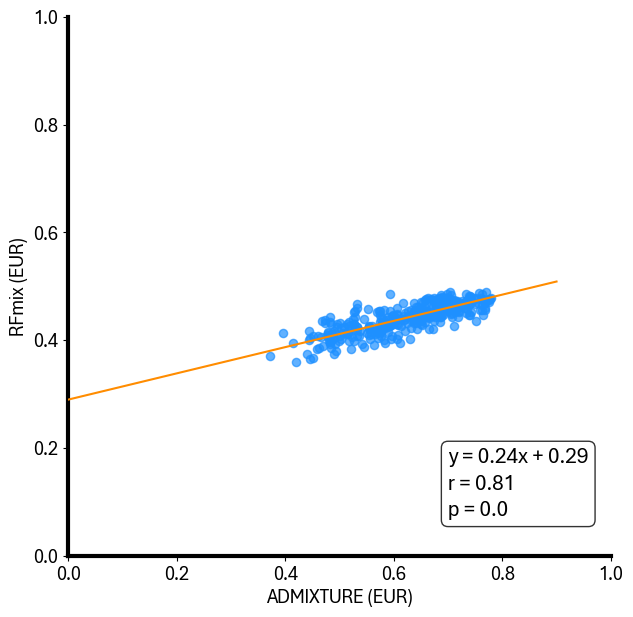

In [88]:
anc = 'EUR'
x_var = anc
y_var = 'RFmix_'+anc
lower, upper = (0, 1)

fig, ax = plt.subplots(figsize=(7, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
#ax.grid(True, axis='both', linestyle='--', alpha=0.7, zorder=0)
ax.tick_params(axis='both', labelsize=14)

ax.scatter(df[x_var], df[y_var], color=anc_color_dict[anc],
           s=35, alpha=0.7, zorder=3)    

# Calculate the linear regression line
slope, intercept, r_value, p_value, std_err = stats.linregress(
    df[x_var], df[y_var])
    
# Plot the regression line
ax.plot(np.arange(lower, upper, 0.1), 
        intercept + slope * np.arange(lower, upper, 0.1), 
       color='darkorange', linestyle='-', zorder=4)

# regression line stats
stats_text = '\n'.join(['y = '+str(slope.round(2))+'x + '+str(intercept.round(2)),
                        'r = %s' % str(r_value.round(2)),
                        'p = %s' % str(p_value.round(4))])
ax.text(0.7, 0.2, stats_text,
    transform=ax.transAxes, fontsize=16, verticalalignment='top',
    horizontalalignment='left',
    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=0.8),
    linespacing=1.5
)

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_xlabel('ADMIXTURE ('+anc+')', fontsize=14)
ax.set_ylabel('RFmix ('+anc+')', fontsize=14)

plt.show()

In [93]:
df['RFmix_sum'] = df[['RFmix_EUR', 'RFmix_AMR', 'RFmix_AFR']].sum(axis=1)
df['sum'] = df[['EUR', 'AMR', 'AFR']].sum(axis=1)